In [ ]:
import os
import yaml
import torch
import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from dotenv import load_dotenv
from transformers import AutoTokenizer
from askwiki.inference.chat import chat_v2
from askwiki.training.config import Config
from askwiki.training.utils import generate_state

load_dotenv()

CHECKPOINT_PATH=os.environ['CHECKPOINTPATH']
CONFIG_PATH=os.environ['CONFIGPATH']
DATA_PATH=os.environ['DATAPATH']

# load most recent checkpoint
state = torch.load(f'{CHECKPOINT_PATH}/sft_latest.pt')

the training looks okay given the loss and grad norm charts, but the loss drop off tells me that the network may have overfitted. the network was trained over 3 epochs of the Q&A response data.

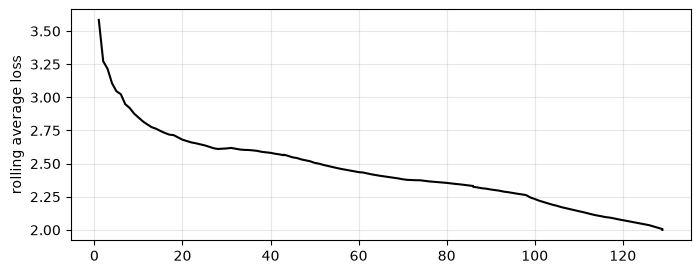

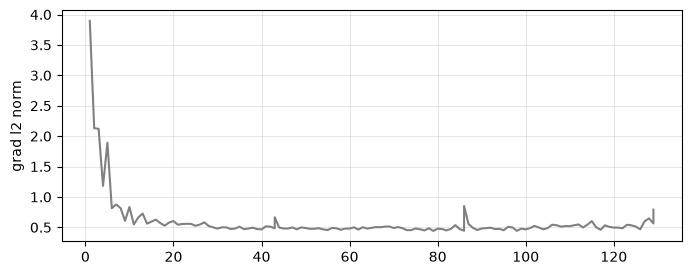

In [35]:
train_hist_df = pd.DataFrame(state['loss_hist'])
train_hist_df['step'] = train_hist_df['step'] + (43 * train_hist_df['epoch'])

# loss history
plt.figure(figsize=(8, 3))
plt.plot(train_hist_df['step'], train_hist_df['loss'], color='black')
plt.ylabel('rolling average loss')
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(8, 3))
plt.plot(train_hist_df['step'], train_hist_df['grad_norm'], color='grey')
plt.ylabel('grad l2 norm')
plt.grid(alpha=0.3)
plt.show()

the most telling will be how the model responds to some examples of prompts. previously, the model was only able to essentially "autocomplete" the beginnings of wikipedia articles; since the net was not trained to respond to questions. it was evident from the pre-training evaluations that the network had not necessarily encoded lots of information or data, but had rather learnt to speak in a 'Wikipedia'-like way.

In [36]:
with open(f'{CONFIG_PATH}/sft.yaml', 'r') as file:
    config = Config(**yaml.safe_load(file)['config'])

device = torch.device('cuda')
tokeniser = AutoTokenizer.from_pretrained("notoverfit/askwiki", subfolder="tokenizer")

# create state object and load in trained net
state_obj = generate_state(config, {'AdamW': torch.optim.AdamW})
state_obj.load_state_dict(state)

it is profound to see that with a small set of samples, that the network has learnt to respond to prompts in a succinct manner. whilst many of the facts that the model returns are clearly wrong, and are a representative of a major problem with LLMs (models sounding confident whilst being wrong), the response quality to prompts posed by the user have improved significantly.

In [ ]:
from askwiki.model.nets.net import TransformerNet

prompts = [
    'What did Marie Curie discover?',
    'Who was Isaac Newton?',
    'What is the capital of France?',
    'Which country is the Great Wall located in?',
    'What language is spoken in Brazil?',
    'Who painted the Mona Lisa?',
    'What is the largest ocean on Earth?',
    'Who was the first person to walk on the Moon?',
    'What is Japan famous for?',
    'Where is Mount Everest?',
]

base_ckpt = torch.load(os.path.expanduser(config.base_model), map_location=device)
base_net = TransformerNet(vocab_size=config.vocab_size, n_dim=config.emb_dim, seq_len=config.seq_len, n_heads=[config.n_heads] * config.num_blocks, mlp_dim=[config.mlp_dim] * config.num_blocks).to(device)
base_net.load_state_dict(base_ckpt['model'])

MAX_NEW_TOKENS = 128
torch.manual_seed(0)

rows = []
for p in prompts:
    # i raise the temperature on the base model as it has a tendency to repeat words at lower temps.
    base_out = chat_v2(base_net, tokeniser, device, p, temperature=1.0, max_new_tokens=MAX_NEW_TOKENS)
    sft_out = chat_v2(state_obj.net, tokeniser, device, p, temperature=0.5, max_new_tokens=MAX_NEW_TOKENS)
    rows.append({'prompt': p, 'base': base_out, 'sft': sft_out})

    print(f'>>> {p}')
    print(textwrap.fill(f'[base] {base_out}', width=110, subsequent_indent='       '))
    print(textwrap.fill(f'[sft]  {sft_out}', width=110, subsequent_indent='       '))
    print()

>>> What did Marie Curie discover?
[base] in Estonian women's styles: "It was apolitical, kindly, and wise."  The way of the promote their
       careers is captured from their Railway Order-comparison by the Estonian engineers, merchants and
       technical Units, who are autonomous motorized passenger trains. In carrying on those matters they
       decipher a certain form of trade pattern. These battlements are replaced by railway general's and
       equitable rail transit methods, which subscribes to the previous reformulation. The task edition is
       found new in Federica's first album "Class Adam."  Early 1900s  ordon Thien is shown as
[sft]  Marie Curie discovered the secret of the biblical Book of Revelation in the mid-14th century.

>>> Who was Isaac Newton?
[base] Anosyntaph. Toddrai Watts: Sext fighting: Dartfield thanAR. Game: Sint Joachim. 1982 - Europe: Sint
       Joachim
[sft]  Isaac Newton (also spelled Isaac Newton) was an English priest who was born in 1653.

>>

: 